# MoE: configuration, schematic, results and routing

Code: `models/moe/` (module + `__init__.py` builder), configs: `models/moe/configs/*.yaml`.
Deviations from the reference: docs/deviations.md. Variants: docs/variant_registry.md.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
from backbone.config import list_variants, load_yaml, variant_path
for v in list_variants("moe"):
    print(f"--- {v}"); print(json.dumps(load_yaml(variant_path("moe", v)).get("structure_params", {})))

--- default
{"num_experts": 8, "expert_hidden": 256, "k": 2, "gate": "mlp", "gate_norm": "renorm", "bias": true, "routing": "learned", "switchloss": 0.01, "zloss": 0.0}
--- hash
{"num_experts": 8, "expert_hidden": 256, "k": 2, "gate": "mlp", "gate_norm": "renorm", "bias": true, "routing": "hash", "switchloss": 0.01, "zloss": 0.0}
--- top1
{"num_experts": 8, "expert_hidden": 256, "k": 1, "gate": "linear", "gate_norm": "raw", "bias": true, "routing": "learned", "switchloss": 0.01, "zloss": 0.0}


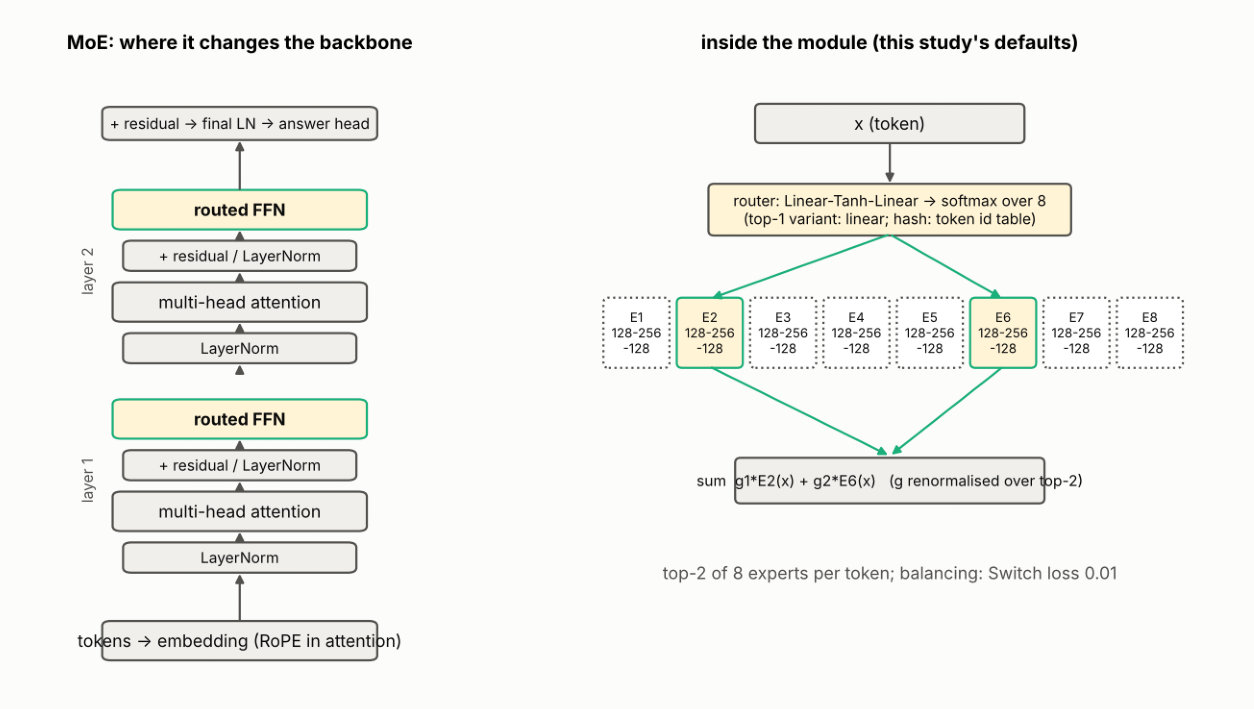

In [3]:
from analysis.schematics import draw
import matplotlib.pyplot as plt, matplotlib.image as mpimg
def show(p, size=(11, 5.5)):
    if p: plt.figure(figsize=size); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()
show(draw("moe"))

In [4]:
from analysis.collect import load_results, load_routing, agg
from analysis import figures as F
df = load_results(RUNS_ROOT); d = df[df.structure == "moe"]
if len(d):
    t = agg(d, ["dataset", "variant", "balance"])
    display(t.pivot_table(index=["dataset", "variant"], columns="balance", values="mean").round(3))
else:
    print("no finished runs yet")

balance             lb   none  warmup
dataset variant                      
copy    default    NaN  1.000     NaN
fact    default  0.651  0.441   0.471
        hash       NaN  0.246     NaN
        top1     0.604  0.582   0.591
logic   default    NaN  0.580     NaN
mix     default    NaN  0.633     NaN
mod     default  0.280  0.269   0.271
mqar    default    NaN  0.125     NaN
rev     default    NaN  1.000     NaN

entropy  max_load   dead
dataset variant balance                          
copy    default none       0.500     0.471  3.500
fact    default lb         0.996     0.153  0.000
                none       0.592     0.458  0.333
                warmup     0.648     0.448  0.167
        hash    none       0.940     0.245  0.000
        top1    lb         0.996     0.148  0.000
                none       0.849     0.379  0.000
                warmup     0.870     0.328  0.000
logic   default none       0.443     0.491  3.000
mix     default none       0.759     0.303  0.500
mod     default lb         0.996     0.149  0.000
                none       0.668     0.430  0.333
                warmup     0.737     0.402  0.167
mqar    default none       0.772     0.349  0.500
rev     default none       0.604     0.431  2.000

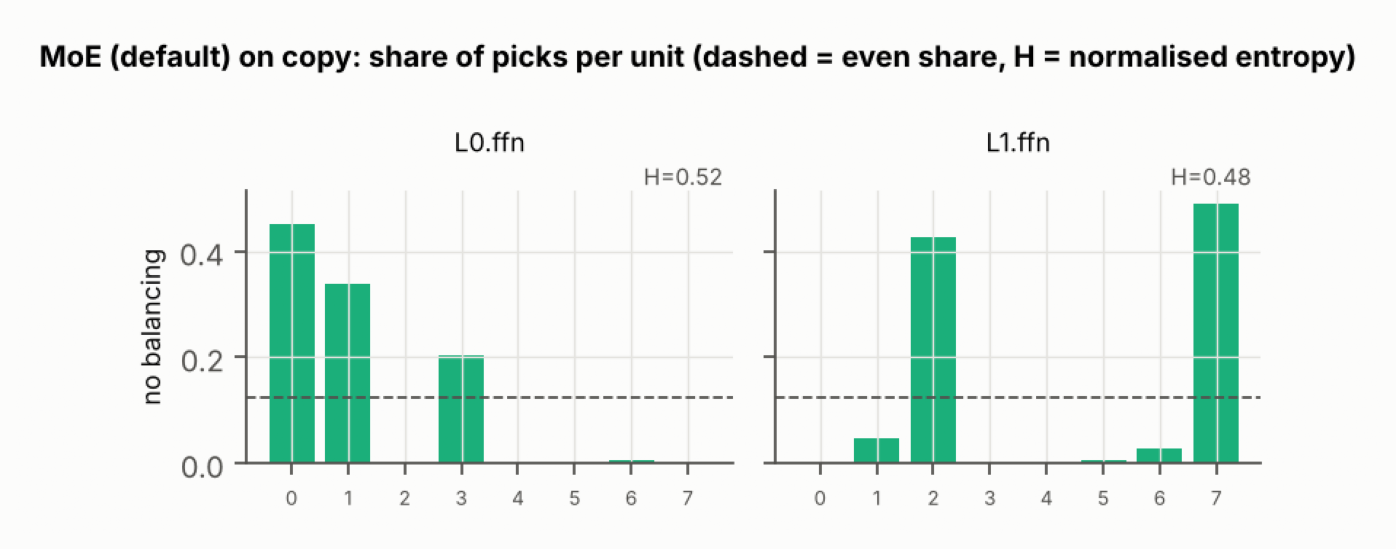

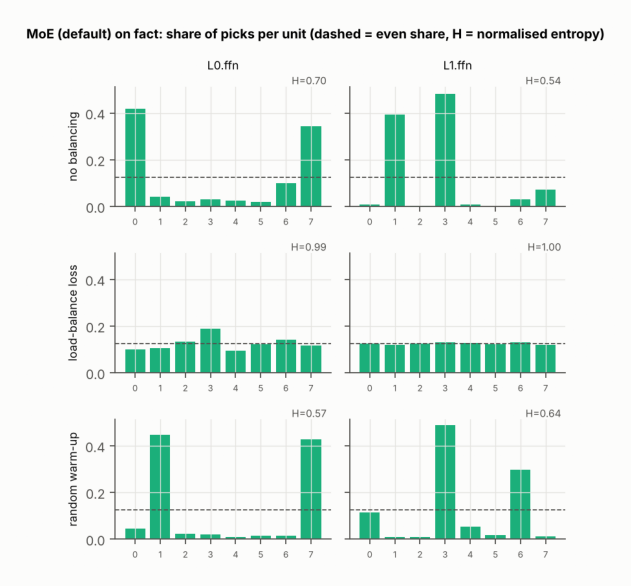

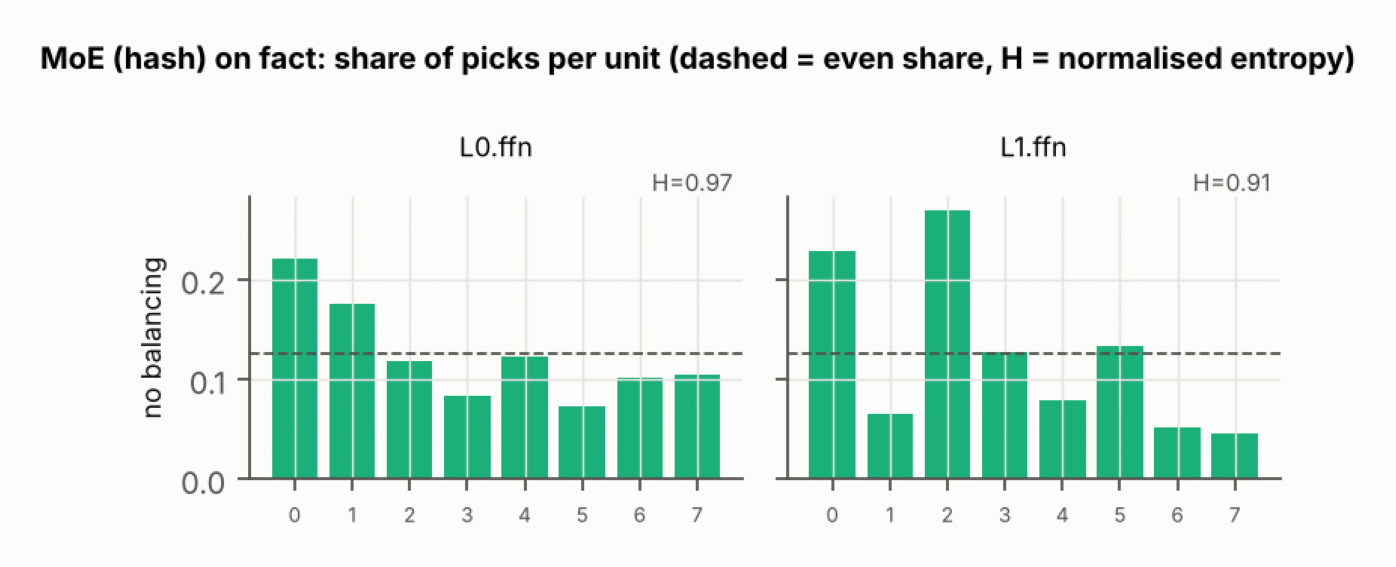

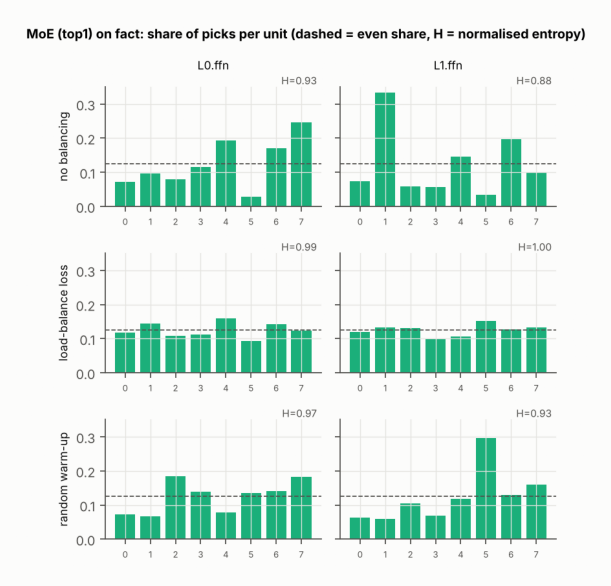

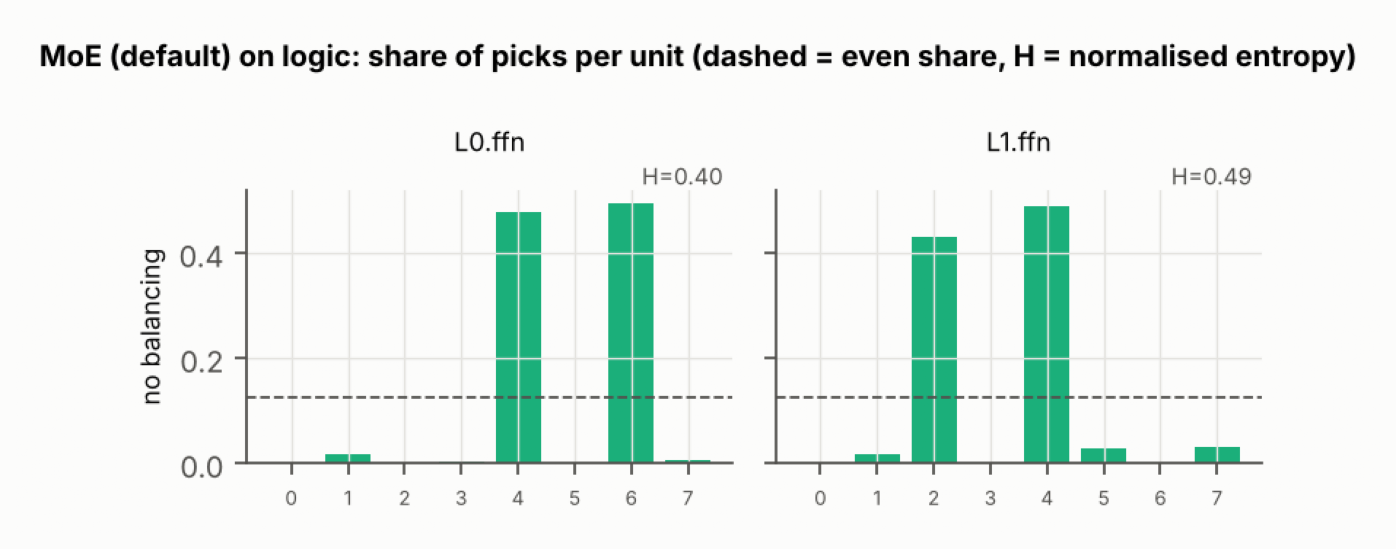

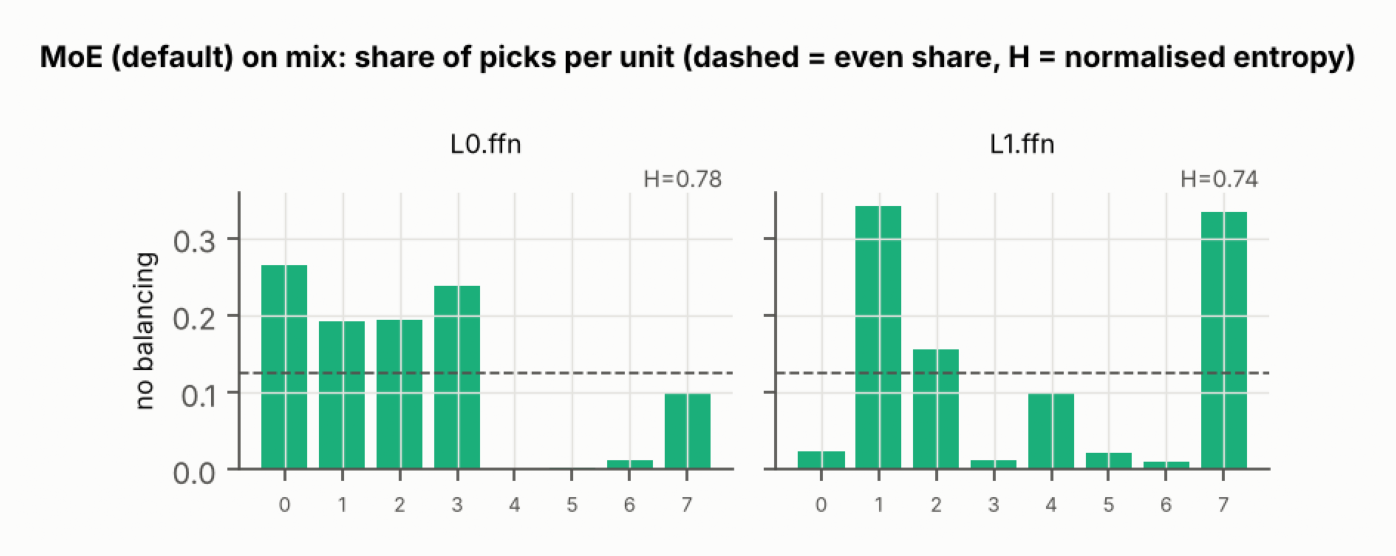

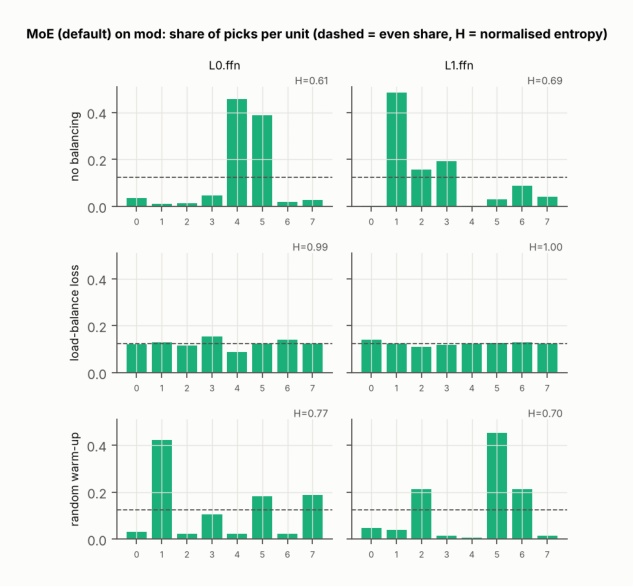

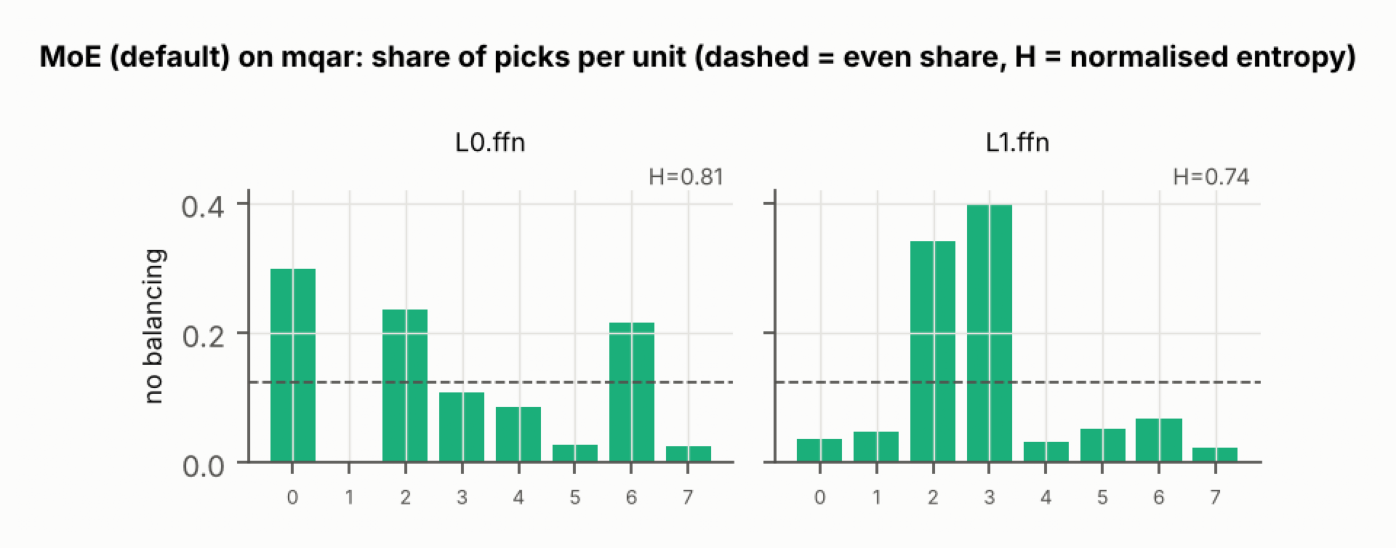

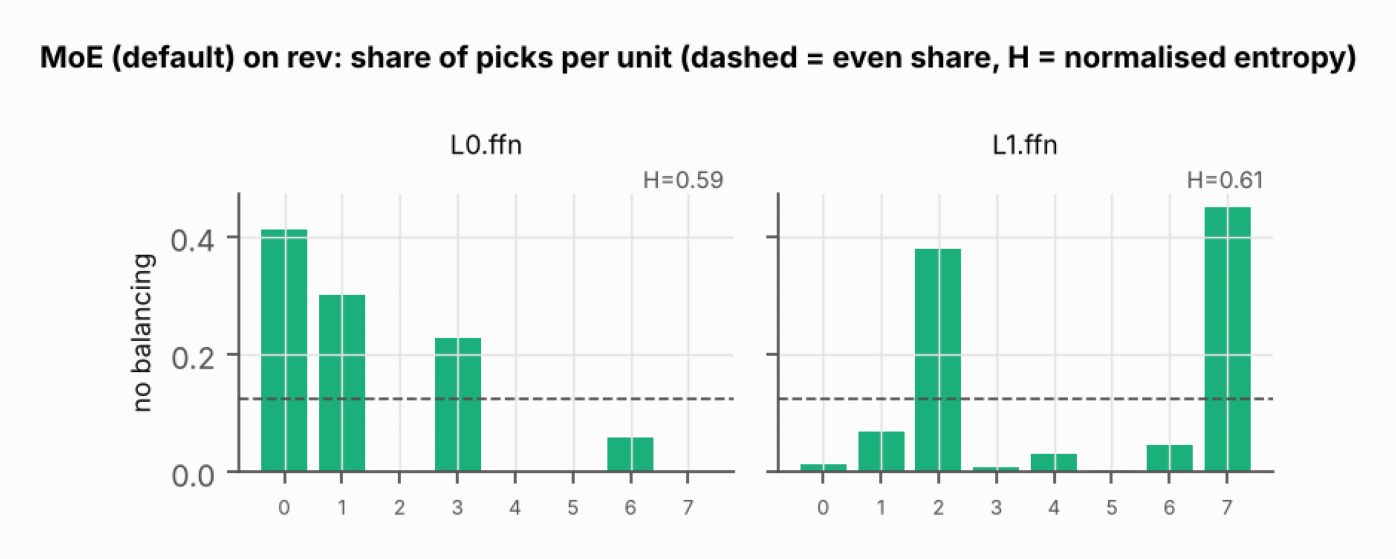

In [5]:
rdf = load_routing(RUNS_ROOT)
if len(rdf) and "moe" in set(rdf.structure):
    r = rdf[rdf.structure == "moe"]
    display(r.groupby(["dataset", "variant", "balance"])[["entropy", "max_load", "dead"]].mean().round(3))
    for ds in sorted(set(r.dataset)):
        for v in sorted(set(r[r.dataset == ds].variant)):
            show(F.routing_load(rdf, ds, "moe", v), (11, 4.5))